# Dense Autoencoder (4 layers) on MNIST - Denoising

A standard 4-layer dense autoencoder that removes 15% gradient noise from handwritten digits, trained on only 2500 / 5000 images.

| Item | Setting |
|---|---|
| Dataset | MNIST (70,000 = 60,000 train + 10,000 test merged) |
| Subset size | 2500 and 5000 |
| Seeding | 42 |
| Split | Train 70% / Test 20% (+15% gradient noise) / Validate 10% |
| Epochs | 50 and 100 |
| Learning rate | 0.01 |
| Model | Dense Autoencoder: 784 - 512 - 256 - 512 - 784 (4 dense layers) |
| Evaluation | Training vs validation loss, result plot of 10 digits, confusion matrix |

How it works:
- **Training:** the input is a noisy, slightly shifted/rotated digit and the target is the clean digit, so the network learns to remove the noise (loss = MSE).
- **Output:** the reconstructed ("Result") image. Lower MSE and higher PSNR mean a better restoration.
- **Optimizer:** Adam with learning rate 0.01 (plain SGD with 0.01 did not train this network in my tests), with batch normalization and cosine learning-rate decay.
- **Test-time augmentation:** the denoised image is averaged over the image and its 8 one-pixel shifts.
- **Confusion matrix:** an autoencoder does not predict digits, so a small helper classifier reads the denoised images. It shows how well digits can still be recognized after denoising.

Files saved in `output/` (same layout for every run):
`epochs_size*_epochs*.csv`, `graph_loss_*.png`, `graph_confusion_*.png`, `graph_samples_*.png`, `result_10_digits_*.png`, plus `graph_summary_comparison.png` and `results.csv`.

## 1. Install dependencies

In [1]:
%pip install -q torch torchvision matplotlib scikit-learn pandas

/mnt/hdd/Y3/ISTAD/AI_Engineer/Standard 4-Layer Dense Autoencoder/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## 2. Configuration

In [2]:
import math
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from torchvision.transforms.functional import gaussian_blur
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# ---- Requirements ----
SEED = 42
SUBSET_SIZES = [2500, 5000]
EPOCH_LIST = [50, 100]
LEARNING_RATE = 0.01
TRAIN_RATIO, TEST_RATIO, VAL_RATIO = 0.70, 0.20, 0.10
NOISE_LEVEL = 0.15          # 15% gradient noise on the test set
MODEL_NAME = "Dense Autoencoder"

# ---- Other settings ----
BATCH_SIZE = 32
WEIGHT_DECAY = 0.0
HIDDEN_UNITS = 512            # width of dense layers 1 and 3
LATENT_UNITS = 256            # width of the bottleneck (dense layer 2)
GEOMETRIC_AUGMENTATION = True  # random small shifts / rotations / scale / shear on the training images
CLASSIFIER_EPOCHS = 30         # helper classifier used for the confusion matrix
NOISY_VALIDATION = True      # True: validation inputs also get the 15% gradient noise (as in the sample CSV, validation loss is close to test MSE). False: validation inputs stay clean
BLUR_SIGMA = 0.8            # slight blur so test images look like the slide; set 0 to disable
DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
print("Device:", DEVICE)

Device: cpu


## 3. Load MNIST (70,000 images)

In [3]:
train_ds = datasets.MNIST(DATA_DIR, train=True, download=True)
test_ds = datasets.MNIST(DATA_DIR, train=False, download=True)

X_all = torch.cat([train_ds.data, test_ds.data]).float().div(255.0).unsqueeze(1)  # (N, 1, 28, 28) in [0, 1]
y_all = torch.cat([train_ds.targets, test_ds.targets])

assert len(y_all) == 70000
print("Total images:", len(y_all), "| image shape:", tuple(X_all.shape[1:]))

100.0%
100.0%
100.0%
100.0%

Total images: 70000 | image shape: (1, 28, 28)


## 4. Subset and split (70% train / 20% test / 10% validate, seed 42)

In [4]:
def make_split(n, seed=SEED):
    # Stratified subset of size n, then stratified 70 / 20 / 10 split.
    all_idx = np.arange(len(y_all))
    idx_sub, _ = train_test_split(
        all_idx, train_size=n, stratify=y_all.numpy(), random_state=seed
    )
    y_sub = y_all[idx_sub].numpy()

    idx_train, idx_rest = train_test_split(
        idx_sub, train_size=TRAIN_RATIO, stratify=y_sub, random_state=seed
    )
    y_rest = y_all[idx_rest].numpy()

    idx_test, idx_val = train_test_split(
        idx_rest,
        train_size=TEST_RATIO / (TEST_RATIO + VAL_RATIO),
        stratify=y_rest,
        random_state=seed,
    )
    return idx_train, idx_val, idx_test


for n in SUBSET_SIZES:
    tr, va, te = make_split(n)
    print(f"N={n}: train={len(tr)} ({len(tr)/n:.0%}), test={len(te)} ({len(te)/n:.0%}), val={len(va)} ({len(va)/n:.0%})")

N=2500: train=1750 (70%), test=500 (20%), val=250 (10%)
N=5000: train=3500 (70%), test=1000 (20%), val=500 (10%)


## 5. Gradient noise (15%) for the test set

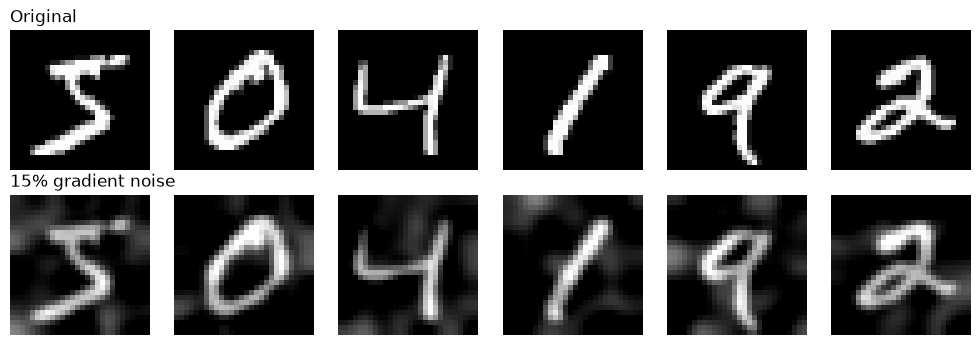

In [5]:
def add_gradient_noise(x, level=NOISE_LEVEL, sigma=2.0, blur_sigma=BLUR_SIGMA, seed=SEED, generator=None):
    # Smooth (low-frequency) noise field whose std equals `level` of the intensity range.
    g = generator if generator is not None else torch.Generator().manual_seed(seed)
    noise = torch.randn(x.shape, generator=g)
    k = int(2 * round(3 * sigma) + 1)
    noise = gaussian_blur(noise, kernel_size=[k, k], sigma=[sigma, sigma])
    noise = noise / noise.flatten(1).std(dim=1).view(-1, 1, 1, 1)
    if torch.is_tensor(level):
        level = level.view(-1, 1, 1, 1)
    out = x + level * noise
    if blur_sigma > 0:
        out = gaussian_blur(out, kernel_size=[3, 3], sigma=[blur_sigma, blur_sigma])
    return out.clamp(0, 1)


# Quick preview
preview = X_all[:6]
preview_noisy = add_gradient_noise(preview)
fig, axes = plt.subplots(2, 6, figsize=(10, 3.5))
for i in range(6):
    axes[0, i].imshow(preview[i, 0], cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(preview_noisy[i, 0], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Original", loc="left")
axes[1, 0].set_title("15% gradient noise", loc="left")
plt.tight_layout()
plt.show()

## 6. Model: Dense Autoencoder (4 dense layers)

In [6]:
class DenseAutoencoder(nn.Module):
    # 4 dense layers: 784 -> 512 -> 256 (bottleneck) -> 512 -> 784
    def __init__(self, hidden=HIDDEN_UNITS, latent=LATENT_UNITS):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),     # dense layer 1 (encoder)
            nn.Linear(hidden, latent), nn.BatchNorm1d(latent), nn.ReLU(),  # dense layer 2 (bottleneck)
            nn.Linear(latent, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),  # dense layer 3 (decoder)
            nn.Linear(hidden, 784), nn.Sigmoid(),                          # dense layer 4 (pixels in 0..1)
        )

    def forward(self, x):
        return self.net(x).view(-1, 1, 28, 28)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(DenseAutoencoder())
print("Trainable parameters:", f"{count_params(DenseAutoencoder()):,}")

DenseAutoencoder(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=512, bias=True)
    (8): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Linear(in_features=512, out_features=784, bias=True)
    (11): Sigmoid()
  )
)
Trainable parameters: 1,069,584


## 7. Training and evaluation functions

In [7]:
def random_affine(x, rot=10, shift=0.07, scale=0.08, shear=0.1):
    # Small random shift / rotation / scale / shear (applied to the clean image, so the target moves too).
    n = x.size(0)
    angle = (torch.rand(n) * 2 - 1) * rot * math.pi / 180
    s = 1 + (torch.rand(n) * 2 - 1) * scale
    tx = (torch.rand(n) * 2 - 1) * shift * 2
    ty = (torch.rand(n) * 2 - 1) * shift * 2
    sh = (torch.rand(n) * 2 - 1) * shear
    theta = torch.zeros(n, 2, 3)
    theta[:, 0, 0] = torch.cos(angle) / s
    theta[:, 0, 1] = (-torch.sin(angle) + sh) / s
    theta[:, 0, 2] = tx
    theta[:, 1, 0] = torch.sin(angle) / s
    theta[:, 1, 1] = torch.cos(angle) / s
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)


def random_corruption(x, max_noise=0.25):
    # Gradient noise + blur similar to the test-set corruption (random strength).
    n = x.size(0)
    level = 0.05 + torch.rand(n) * (max_noise - 0.05)
    gen = torch.Generator().manual_seed(int(torch.randint(0, 10**9, (1,))))
    out = add_gradient_noise(x, level=level, blur_sigma=0, generator=gen)
    if random.random() < 0.8:
        sigma = random.uniform(0.5, 1.0)
        out = gaussian_blur(out, kernel_size=[3, 3], sigma=[sigma, sigma])
    return out


@torch.no_grad()
def evaluate_ae(model, X_noisy, X_clean, batch_size=1000):
    # Returns MSE and MAE between the model output (from the noisy input) and the clean image.
    model.eval()
    sq = ab = 0.0
    for i in range(0, len(X_clean), batch_size):
        out = model(X_noisy[i:i + batch_size].to(DEVICE)).cpu()
        diff = out - X_clean[i:i + batch_size]
        sq += (diff ** 2).sum().item()
        ab += diff.abs().sum().item()
    return sq / X_clean.numel(), ab / X_clean.numel()


@torch.no_grad()
def denoise(model, X, tta=False, batch_size=500):
    # Denoised images. With tta=True the result is averaged over the image and its 8 one-pixel shifts.
    model.eval()
    shifts = [(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1)] if tta else [(0, 0)]
    out = []
    for i in range(0, len(X), batch_size):
        xb = X[i:i + batch_size].to(DEVICE)
        acc = sum(torch.roll(model(torch.roll(xb, sh, dims=(2, 3))), (-sh[0], -sh[1]), dims=(2, 3)) for sh in shifts)
        out.append((acc / len(shifts)).cpu())
    return torch.cat(out)


def train_model(X_tr, X_val_noisy, X_val_clean, epochs, X_test_noisy, X_test_clean, log_path=None):
    # Trains the autoencoder and writes one CSV row per epoch (same 8 columns as the sample CSV).
    set_seed()
    model = DenseAutoencoder().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loader = DataLoader(
        TensorDataset(X_tr),
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(loader))
    hist = {"train_loss": [], "val_loss": []}
    rows = []

    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        model.train()
        run_mse = run_mae = 0.0
        seen = 0
        for (clean,) in loader:
            if GEOMETRIC_AUGMENTATION:
                clean = random_affine(clean)
            noisy = random_corruption(clean)
            clean, noisy = clean.to(DEVICE), noisy.to(DEVICE)
            optimizer.zero_grad()
            out = model(noisy)
            loss = F.mse_loss(out, clean)
            loss.backward()
            optimizer.step()
            scheduler.step()
            run_mse += loss.item() * len(clean)
            run_mae += (out - clean).abs().mean().item() * len(clean)
            seen += len(clean)

        train_loss, train_mae = run_mse / seen, run_mae / seen
        val_loss, val_mae = evaluate_ae(model, X_val_noisy, X_val_clean)
        test_mse, _ = evaluate_ae(model, X_test_noisy, X_test_clean)
        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)

        if log_path is not None:
            rows.append({
                "Epoch": epoch,
                "Train Loss": train_loss,
                "Val Loss": val_loss,
                "Train MAE": train_mae,
                "Val MAE": val_mae,
                "Test MSE": test_mse,
                "Loss Gap (Val-Train)": val_loss - train_loss,
                "Epoch Time (s)": time.perf_counter() - epoch_start,
            })
            pd.DataFrame(rows).to_csv(log_path, index=False)   # rewritten every epoch, so nothing is lost

        if epoch % 10 == 0 or epoch == 1:
            print(f"  epoch {epoch:3d}/{epochs} | train MSE {train_loss:.5f} | val MSE {val_loss:.5f} | test MSE {test_mse:.5f}")
    return model, hist

## 8. Helper classifier (only used for the confusion matrix)

In [8]:
class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, 10))

    def forward(self, x):
        return self.net((x - 0.1307) / 0.3081)


def train_digit_classifier(autoencoder, X_tr, y_tr, epochs=CLASSIFIER_EPOCHS):
    # Trained on the training images only: clean images + their denoised copies.
    set_seed()
    denoised = [denoise(autoencoder, random_corruption(random_affine(X_tr))) for _ in range(2)]
    X_all_tr = torch.cat([X_tr] + denoised)
    y_all_tr = torch.cat([y_tr] * 3)
    clf = DigitClassifier().to(DEVICE)
    optimizer = torch.optim.SGD(clf.parameters(), lr=LEARNING_RATE, momentum=0.9, nesterov=True)
    loader = DataLoader(TensorDataset(X_all_tr, y_all_tr), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(loader))
    for _ in range(epochs):
        clf.train()
        for xb, yb in loader:
            xb = random_affine(xb).to(DEVICE)
            optimizer.zero_grad()
            F.cross_entropy(clf(xb), yb.to(DEVICE)).backward()
            optimizer.step()
            scheduler.step()
    return clf


@torch.no_grad()
def classify(clf, X, batch_size=1000):
    clf.eval()
    return torch.cat([clf(X[i:i + batch_size].to(DEVICE)).argmax(1).cpu() for i in range(0, len(X), batch_size)])

## 9. Run experiments (sizes 2500 and 5000 x epochs 50 and 100)

In [9]:
results = {}

for n in SUBSET_SIZES:
    idx_train, idx_val, idx_test = make_split(n)
    X_tr, y_tr = X_all[idx_train], y_all[idx_train]
    X_val_clean = X_all[idx_val]
    X_te, y_te = X_all[idx_test], y_all[idx_test]
    X_te_noisy = add_gradient_noise(X_te)                      # the test set gets 15% gradient noise
    X_val_noisy = add_gradient_noise(X_val_clean, seed=SEED + 1) if NOISY_VALIDATION else X_val_clean
    input_mse = F.mse_loss(X_te_noisy, X_te).item()            # error of the noisy image itself (what we must beat)

    for epochs in EPOCH_LIST:
        print(f"\n=== {MODEL_NAME} | size={n} | epochs={epochs} ===")
        log_path = OUTPUT_DIR / f"epochs_size{n}_epochs{epochs}.csv"
        t0 = time.perf_counter()
        model, hist = train_model(X_tr, X_val_noisy, X_val_clean, epochs, X_te_noisy, X_te, log_path=log_path)
        elapsed = time.perf_counter() - t0
        print(f"  Epoch log saved: {log_path}")

        test_mse, test_mae = evaluate_ae(model, X_te_noisy, X_te)
        X_den = denoise(model, X_te_noisy, tta=True)           # final result uses test-time augmentation
        test_mse_tta = F.mse_loss(X_den, X_te).item()
        psnr = 10 * math.log10(1 / test_mse_tta)

        clf = train_digit_classifier(model, X_tr, y_tr)
        pred_noisy, pred_den = classify(clf, X_te_noisy), classify(clf, X_den)
        acc_noisy = (pred_noisy == y_te).float().mean().item()
        acc_den = (pred_den == y_te).float().mean().item()

        print(f"  Test MSE: noisy input {input_mse:.5f} -> autoencoder {test_mse:.5f} -> with TTA {test_mse_tta:.5f} "
              f"(PSNR {psnr:.2f} dB) | time {elapsed:.1f}s")
        print(f"  Digit accuracy (helper classifier): noisy image {acc_noisy:.4f} -> denoised image {acc_den:.4f}")

        results[(n, epochs)] = {
            "model": model, "hist": hist, "X_te": X_te, "X_te_noisy": X_te_noisy, "X_den": X_den,
            "y_te": y_te, "pred_den": pred_den, "input_mse": input_mse, "test_mse": test_mse,
            "test_mse_tta": test_mse_tta, "test_mae": test_mae, "psnr": psnr,
            "acc_noisy": acc_noisy, "acc_den": acc_den, "time": elapsed,
        }


=== Dense Autoencoder | size=2500 | epochs=50 ===
  epoch   1/50 | train MSE 0.04901 | val MSE 0.03904 | test MSE 0.03784
  epoch  10/50 | train MSE 0.01879 | val MSE 0.01990 | test MSE 0.01922
  epoch  20/50 | train MSE 0.01493 | val MSE 0.01615 | test MSE 0.01569
  epoch  30/50 | train MSE 0.01282 | val MSE 0.01414 | test MSE 0.01374
  epoch  40/50 | train MSE 0.01146 | val MSE 0.01258 | test MSE 0.01236
  epoch  50/50 | train MSE 0.01112 | val MSE 0.01225 | test MSE 0.01197
  Epoch log saved: output/epochs_size2500_epochs50.csv
  Test MSE: noisy input 0.01950 -> autoencoder 0.01197 -> with TTA 0.01140 (PSNR 19.43 dB) | time 21.6s
  Digit accuracy (helper classifier): noisy image 0.8800 -> denoised image 0.9600

=== Dense Autoencoder | size=2500 | epochs=100 ===
  epoch   1/100 | train MSE 0.04901 | val MSE 0.03899 | test MSE 0.03779
  epoch  10/100 | train MSE 0.01895 | val MSE 0.02025 | test MSE 0.01961
  epoch  20/100 | train MSE 0.01539 | val MSE 0.01693 | test MSE 0.01634
  epo

## 10. Summary table (results.csv)

In [10]:
rows = []
for (n, epochs), r in results.items():
    rows.append({
        "Model": MODEL_NAME,
        "Size": n,
        "Epochs": epochs,
        "Params": count_params(r["model"]),
        "Train MSE": round(r["hist"]["train_loss"][-1], 5),
        "Val MSE": round(r["hist"]["val_loss"][-1], 5),
        "Noisy input MSE": round(r["input_mse"], 5),
        "Test MSE": round(r["test_mse"], 5),
        "Test MSE + TTA": round(r["test_mse_tta"], 5),
        "Test PSNR (dB)": round(r["psnr"], 2),
        "Digit acc (noisy image)": round(r["acc_noisy"], 4),
        "Digit acc (denoised image)": round(r["acc_den"], 4),
        "Time (s)": round(r["time"], 1),
    })

summary = pd.DataFrame(rows)
summary.to_csv(OUTPUT_DIR / "results.csv", index=False)
summary

,Model,Size,Epochs,Params,Train MSE,Val MSE,Noisy input MSE,Test MSE,Test MSE + TTA,Test PSNR (dB),Digit acc (noisy image),Digit acc (denoised image),Time (s)
0,Dense Autoencoder,2500,50,1069584,0.01112,0.01225,0.01950,0.01197,0.01140,19.43,0.880,0.960,21.6
1,Dense Autoencoder,2500,100,1069584,0.00918,0.01043,0.01950,0.01015,0.00972,20.12,0.872,0.966,47.0
2,Dense Autoencoder,5000,50,1069584,0.00928,0.01029,0.01959,0.01041,0.01005,19.98,0.890,0.967,50.3
3,Dense Autoencoder,5000,100,1069584,0.00790,0.00874,0.01959,0.00884,0.00854,20.68,0.884,0.970,104.4


## 11. Graphs for every run (saved to output/)

Best configuration: size=5000, epochs=100 (test MSE with TTA 0.00854)


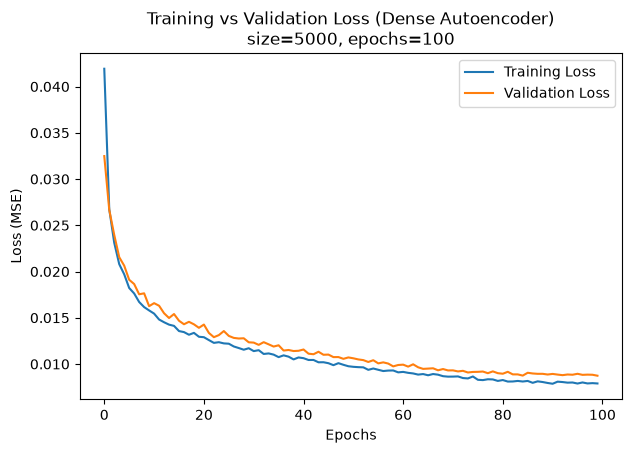

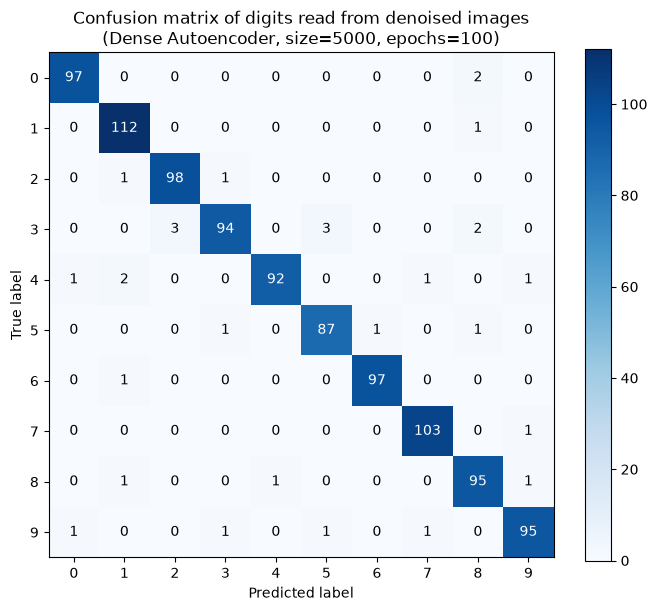

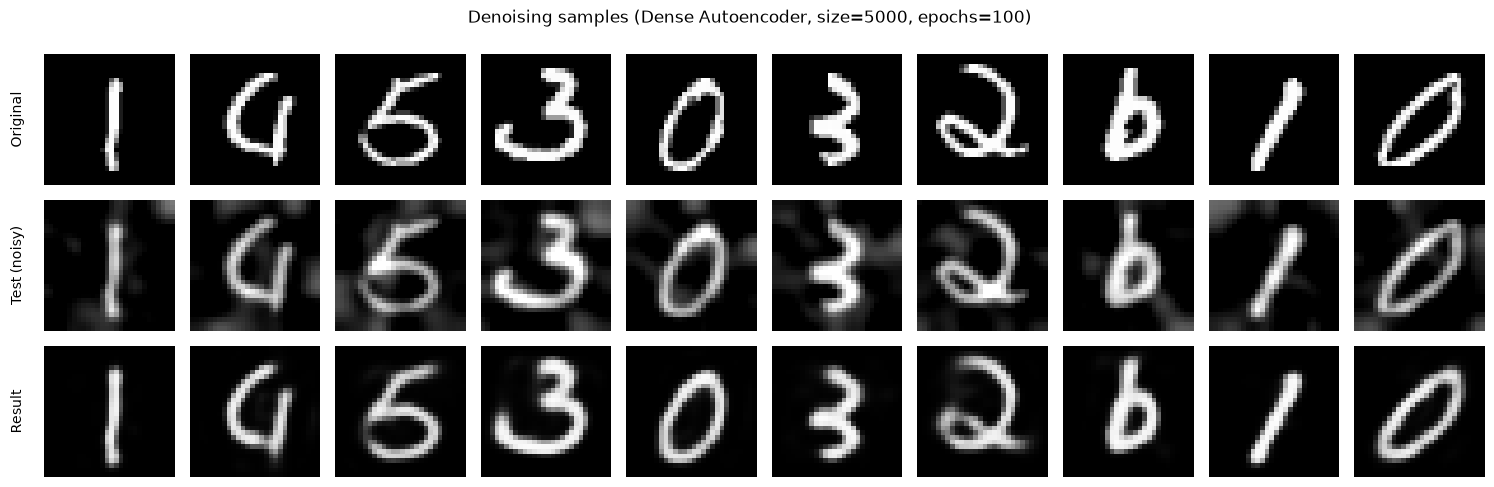

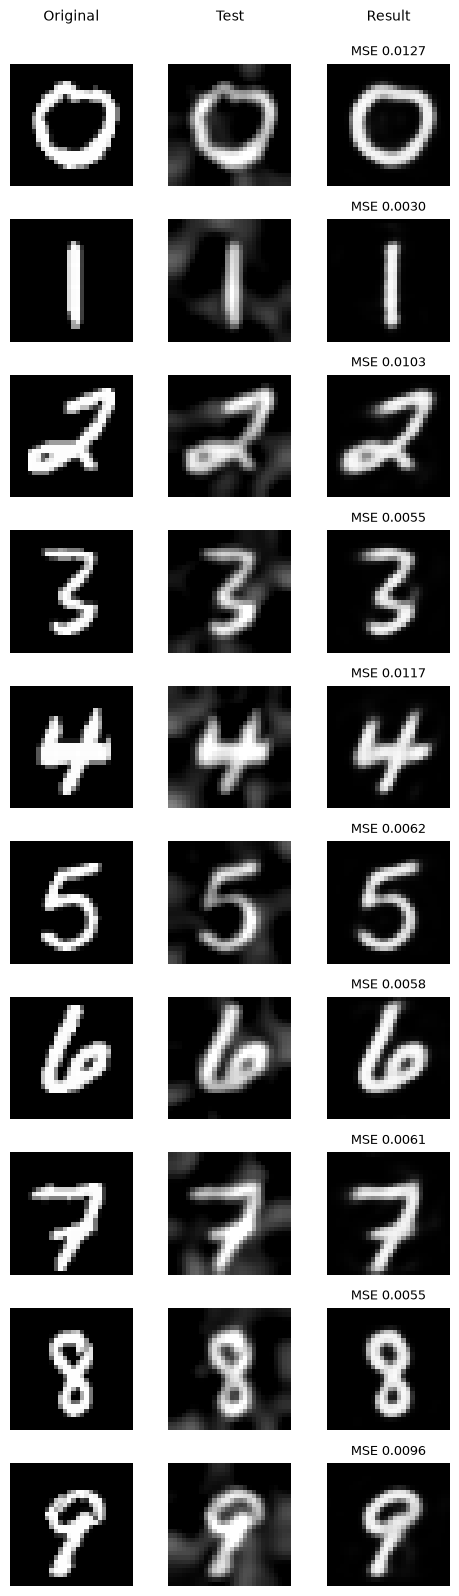

Saved graphs for 4 runs in output


In [11]:
best_key = min(results, key=lambda k: results[k]["test_mse_tta"])
print(f"Best configuration: size={best_key[0]}, epochs={best_key[1]} "
      f"(test MSE with TTA {results[best_key]['test_mse_tta']:.5f})")


def plot_loss(hist, n, epochs):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(hist["train_loss"], label="Training Loss")
    ax.plot(hist["val_loss"], label="Validation Loss")
    ax.set_title(f"Training vs Validation Loss ({MODEL_NAME})\nsize={n}, epochs={epochs}")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Loss (MSE)")
    ax.legend()
    return fig


def plot_confusion(y_true, y_pred, n, epochs):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"Confusion matrix of digits read from denoised images\n({MODEL_NAME}, size={n}, epochs={epochs})")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    fig.colorbar(im, ax=ax)
    thresh = cm.max() / 2
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    fig.tight_layout()
    return fig


def plot_samples(r, n, epochs, count=10):
    # Random test images: original / noisy test / denoised result.
    idx = np.random.RandomState(SEED).choice(len(r["y_te"]), count, replace=False)
    fig, axes = plt.subplots(3, count, figsize=(1.5 * count, 5))
    for col, i in enumerate(idx):
        for row, img in enumerate([r["X_te"][i, 0], r["X_te_noisy"][i, 0], r["X_den"][i, 0]]):
            axes[row, col].imshow(img, cmap="gray", vmin=0, vmax=1)
            axes[row, col].axis("off")
    for row, name in enumerate(["Original", "Test (noisy)", "Result"]):
        axes[row, 0].text(-0.15, 0.5, name, rotation=90, va="center", ha="right", transform=axes[row, 0].transAxes)
    fig.suptitle(f"Denoising samples ({MODEL_NAME}, size={n}, epochs={epochs})")
    fig.tight_layout()
    return fig


def plot_10_digits(r, n, epochs):
    # One test image per digit 0-9: Original / Test (noisy) / Result (denoised).
    y_te = r["y_te"]
    idx = [int((y_te == d).nonzero()[0]) for d in range(10)]
    fig, axes = plt.subplots(10, 3, figsize=(5, 16))
    for row, i in enumerate(idx):
        axes[row, 0].imshow(r["X_te"][i, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, 1].imshow(r["X_te_noisy"][i, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, 2].imshow(r["X_den"][i, 0], cmap="gray", vmin=0, vmax=1)
        img_mse = F.mse_loss(r["X_den"][i], r["X_te"][i]).item()
        axes[row, 2].set_title(f"MSE {img_mse:.4f}", fontsize=9)
        for c in range(3):
            axes[row, c].axis("off")
    for c, name in enumerate(["Original", "Test", "Result"]):
        axes[0, c].text(0.5, 1.35, name, ha="center", transform=axes[0, c].transAxes)
    fig.tight_layout()
    return fig


def save_fig(fig, filename, show=False):
    fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


for (n, epochs), r in results.items():
    show = (n, epochs) == best_key          # display only the best run in the notebook
    tag = f"size{n}_epochs{epochs}"
    save_fig(plot_loss(r["hist"], n, epochs), f"graph_loss_{tag}.png", show)
    save_fig(plot_confusion(r["y_te"].numpy(), r["pred_den"].numpy(), n, epochs), f"graph_confusion_{tag}.png", show)
    save_fig(plot_samples(r, n, epochs), f"graph_samples_{tag}.png", show)
    save_fig(plot_10_digits(r, n, epochs), f"result_10_digits_{tag}.png", show)

print("Saved graphs for", len(results), "runs in", OUTPUT_DIR)

## 12. Loss curves of all four runs

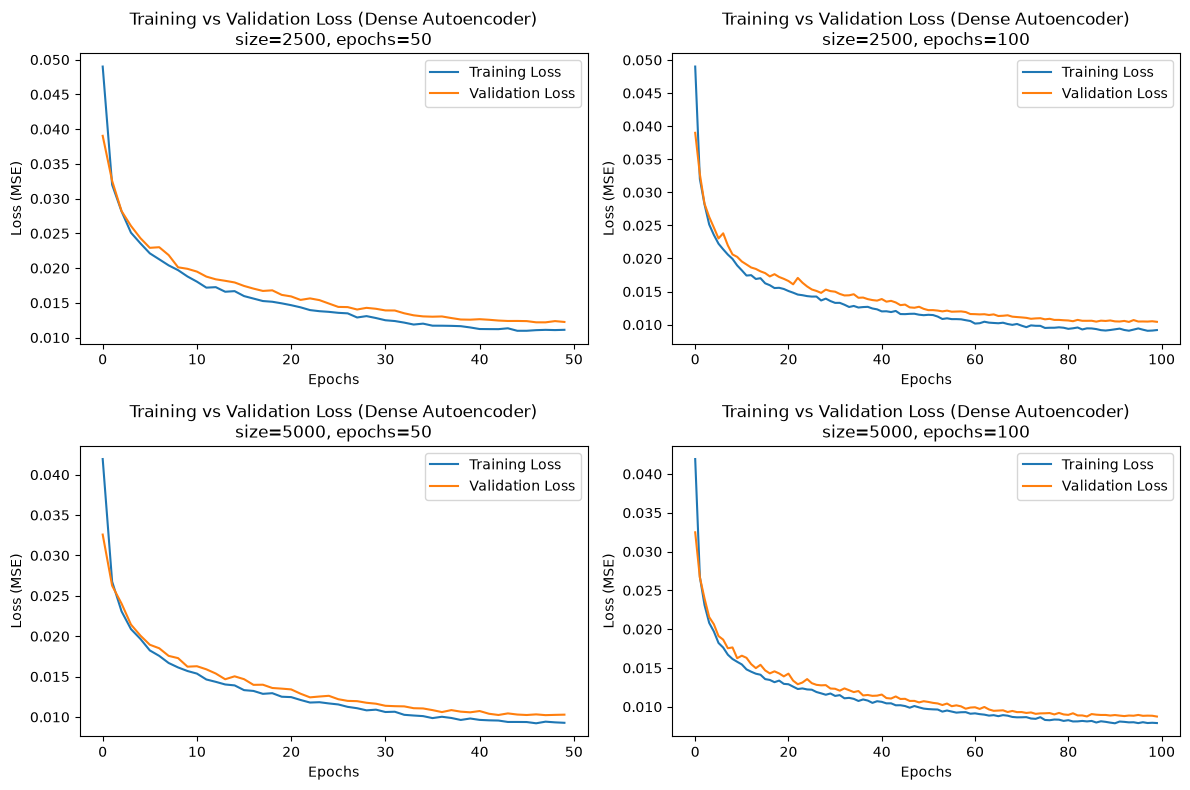

In [12]:
fig, axes = plt.subplots(len(SUBSET_SIZES), len(EPOCH_LIST), figsize=(12, 8))
for row, n in enumerate(SUBSET_SIZES):
    for col, epochs in enumerate(EPOCH_LIST):
        h = results[(n, epochs)]["hist"]
        ax = axes[row, col]
        ax.plot(h["train_loss"], label="Training Loss")
        ax.plot(h["val_loss"], label="Validation Loss")
        ax.set_title(f"Training vs Validation Loss ({MODEL_NAME})\nsize={n}, epochs={epochs}")
        ax.set_xlabel("Epochs")
        ax.set_ylabel("Loss (MSE)")
        ax.legend()
plt.tight_layout()
plt.show()

## 13. Summary comparison (graph_summary_comparison.png)

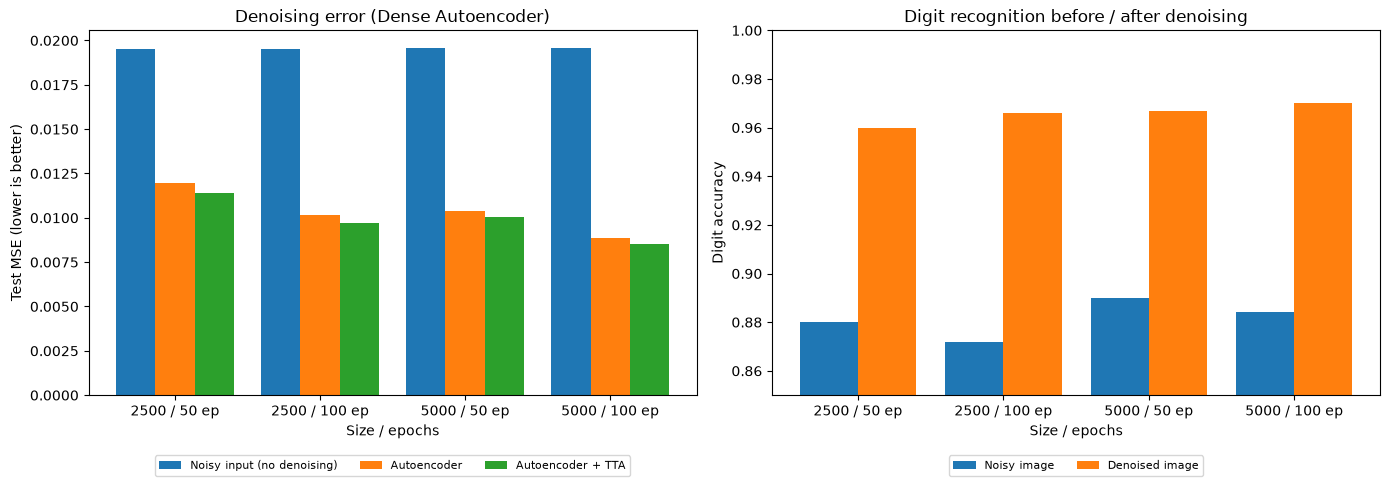

In [13]:
labels = [f"{n} / {e} ep" for (n, e) in results]
x = np.arange(len(labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: reconstruction error (lower is better)
axes[0].bar(x - 0.27, summary["Noisy input MSE"], 0.27, label="Noisy input (no denoising)")
axes[0].bar(x, summary["Test MSE"], 0.27, label="Autoencoder")
axes[0].bar(x + 0.27, summary["Test MSE + TTA"], 0.27, label="Autoencoder + TTA")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_xlabel("Size / epochs"); axes[0].set_ylabel("Test MSE (lower is better)")
axes[0].set_title(f"Denoising error ({MODEL_NAME})")
axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

# Right: digit recognition by the helper classifier (higher is better)
axes[1].bar(x - 0.2, summary["Digit acc (noisy image)"], 0.4, label="Noisy image")
axes[1].bar(x + 0.2, summary["Digit acc (denoised image)"], 0.4, label="Denoised image")
low = float(summary[["Digit acc (noisy image)", "Digit acc (denoised image)"]].min().min())
axes[1].set_ylim(max(0.0, np.floor((low - 0.02) * 20) / 20), 1.0)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_xlabel("Size / epochs"); axes[1].set_ylabel("Digit accuracy")
axes[1].set_title("Digit recognition before / after denoising")
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "graph_summary_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Classification report and best model

In [14]:
best = results[best_key]
print(classification_report(best["y_te"].numpy(), best["pred_den"].numpy(), digits=4))

save_path = OUTPUT_DIR / f"dense_autoencoder_size{best_key[0]}_ep{best_key[1]}.pt"
torch.save(best["model"].state_dict(), save_path)
print("Saved:", save_path)
print("Files in output/:", len(list(OUTPUT_DIR.glob("*"))))

              precision    recall  f1-score   support

           0     0.9798    0.9798    0.9798        99
           1     0.9573    0.9912    0.9739       113
           2     0.9703    0.9800    0.9751       100
           3     0.9691    0.9216    0.9447       102
           4     0.9892    0.9485    0.9684        97
           5     0.9560    0.9667    0.9613        90
           6     0.9898    0.9898    0.9898        98
           7     0.9810    0.9904    0.9856       104
           8     0.9406    0.9694    0.9548        98
           9     0.9694    0.9596    0.9645        99

    accuracy                         0.9700      1000
   macro avg     0.9702    0.9697    0.9698      1000
weighted avg     0.9702    0.9700    0.9699      1000

Saved: output/dense_autoencoder_size5000_ep100.pt
Files in output/: 23
